In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score

SEED = 42               # makes every random step repeatable
BASELINE_CHURN = 0.05   # static churn assumption used by the CLV portal today
HORIZON_YEARS = 15      # CLV horizon from the brief
MODEL_VERSION = "v1.0"
RUN_ID = "RUN_01"

/Users/rameshmandava/Desktop/NewPURE/venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load the raw data
df = pd.read_csv("data/raw/Case_Study_2_CLV_Predictive_Analytics.csv", parse_dates=["contract_end_date"])

# Snapshot date = earliest contract end date in the data (used to turn dates into day counts)
SCORE_DATE = df["contract_end_date"].min()

print(df.shape)
print("Score date:", SCORE_DATE.date())
print(df.dtypes)
df.head()

(2000, 9)
Score date: 2026-10-01
account_id                                object
array_id                                  object
contract_end_date                 datetime64[ns]
historical_15yr_net_profit_usd             int64
current_capacity_tb                        int64
utilization_rate_pct                     float64
static_baseline_churn_rate               float64
churn_event_next_12m                     float64
expansion_potential_signal                object
dtype: object


,account_id,array_id,contract_end_date,historical_15yr_net_profit_usd,current_capacity_tb,utilization_rate_pct,static_baseline_churn_rate,churn_event_next_12m,expansion_potential_signal
0,ACC_1000,ARR_5000,2026-10-01,146797,1382,0.59,0.05,0.0,Medium
1,ACC_1001,ARR_5001,2026-10-01,1236408,1809,0.93,0.05,1.0,UNKNOWN
2,ACC_1002,ARR_5002,2026-10-02,2790632,605,1.28,0.05,0.0,Low
3,ACC_1003,ARR_5003,2026-10-02,1233288,1567,0.47,0.05,0.0,Low
4,ACC_1004,ARR_5004,2026-10-03,2881167,488,1.22,0.05,0.0,Low


In [3]:
# Data quality audit: find the 4 injected anomalies before touching anything
print("Rows:", len(df), "| accounts:", df["account_id"].nunique(), "| arrays:", df["array_id"].nunique())
print("Duplicate rows:", df.duplicated().sum())
print("Static baseline values:", df["static_baseline_churn_rate"].unique())
print()
print("1) Utilization above 100%:", (df["utilization_rate_pct"] > 1).sum(), "rows, max =", df["utilization_rate_pct"].max())
print("2) Negative net profit:", (df["historical_15yr_net_profit_usd"] < 0).sum(), "rows, min =", df["historical_15yr_net_profit_usd"].min())
print("3) Missing churn label:", df["churn_event_next_12m"].isna().sum(), "rows")
print("4) Expansion signal values:")
print(df["expansion_potential_signal"].value_counts())

Rows: 2000 | accounts: 1000 | arrays: 2000
Duplicate rows: 0
Static baseline values: [0.05]

1) Utilization above 100%: 862 rows, max = 1.45
2) Negative net profit: 58 rows, min = -93780
3) Missing churn label: 116 rows
4) Expansion signal values:
expansion_potential_signal
Low        841
Medium     622
High       426
UNKNOWN    111
Name: count, dtype: int64


In [4]:
# Feature pipeline. No row is dropped: each anomaly is kept and turned into features.
def build_features(data):
    features = pd.DataFrame(index=data.index)

    # Utilization is a fraction of capacity, so values above 1.0 (100%) are out of bounds.
    # 43% of rows are above 1.0, so capping alone would flatten them all to the same value.
    # Keep the capped value, a flag, and how far above 1.0 the array is.
    util = data["utilization_rate_pct"]
    features["utilization_capped"] = util.clip(upper=1.0)
    features["util_over_100_flag"] = (util > 1.0).astype(int)
    features["util_excess"] = (util - 1.0).clip(lower=0)

    # log(x) fails on negative profit, so use a signed log: sign(x) * log(1 + |x|).
    profit = data["historical_15yr_net_profit_usd"]
    features["profit_signed_log"] = np.sign(profit) * np.log1p(profit.abs())
    features["is_loss_making"] = (profit < 0).astype(int)

    features["capacity_tb"] = data["current_capacity_tb"]
    features["days_to_contract_end"] = (data["contract_end_date"] - SCORE_DATE).dt.days

    # UNKNOWN is kept as its own category instead of being filled with the most common value.
    for level in ["Low", "Medium", "High", "UNKNOWN"]:
        features["expansion_" + level] = (data["expansion_potential_signal"] == level).astype(int)
    return features


# Cohorts for the back-test. 
df["cohort_contract_end_year"] = df["contract_end_date"].dt.year
df["cohort_capacity_tier"] = pd.qcut(df["current_capacity_tb"], 3, labels=["Entry", "Mid", "Enterprise"])
df["cohort_expansion_signal"] = df["expansion_potential_signal"]
df["cohort_utilization"] = np.where(df["utilization_rate_pct"] > 1.0, "Over 100%", "Up to 100%")
df["cohort_profit"] = np.where(df["historical_15yr_net_profit_usd"] < 0, "Loss-making", "Profitable")

X_all = build_features(df)
X_all.describe().T

,count,mean,std,min,25%,50%,75%,max
utilization_capped,2000.0,0.821545,0.210696,0.350000,0.6600,0.930000,1.000000,1.000000
util_over_100_flag,2000.0,0.431000,0.495340,0.000000,0.0000,0.000000,1.000000,1.000000
util_excess,2000.0,0.095495,0.138026,0.000000,0.0000,0.000000,0.180000,0.450000
profit_signed_log,2000.0,13.584928,4.270333,-11.448718,13.8122,14.573663,15.002512,15.319327
is_loss_making,2000.0,0.029000,0.167848,0.000000,0.0000,0.000000,0.000000,1.000000
capacity_tb,2000.0,1282.771000,699.754635,53.000000,673.5000,1305.500000,1880.000000,2498.000000
days_to_contract_end,2000.0,499.500000,288.747186,0.000000,249.7500,499.500000,749.250000,999.000000
expansion_Low,2000.0,0.420500,0.493763,0.000000,0.0000,0.000000,1.000000,1.000000
expansion_Medium,2000.0,0.311000,0.463019,0.000000,0.0000,0.000000,1.000000,1.000000
expansion_High,2000.0,0.213000,0.409530,0.000000,0.0000,0.000000,0.000000,1.000000


In [5]:
# Isolate the 116 rows with no label BEFORE any training. They become the scoring set.
labelled = df[df["churn_event_next_12m"].notna()].copy()
unlabelled = df[df["churn_event_next_12m"].isna()].copy()

X = X_all.loc[labelled.index]
y = labelled["churn_event_next_12m"].astype(int)
groups = labelled["account_id"]   # each account has 2 arrays; they must stay in the same fold

print("Labelled:", len(labelled), "| unlabelled (scoring set):", len(unlabelled))
print("Actual churn rate:", round(y.mean(), 4))

Labelled: 1884 | unlabelled (scoring set): 116
Actual churn rate: 0.1582


In [6]:

n = len(y)
actual_rate = y.mean()
standard_error = np.sqrt(actual_rate * (1 - actual_rate) / n)

print("Arrays with a known outcome:", n)
print("Churners expected by the 5% rule:", round(n * BASELINE_CHURN, 1))
print("Churners that actually happened:", y.sum())
print("Actual churn rate: {:.2%}  (95% CI {:.2%} to {:.2%})".format(
    actual_rate, actual_rate - 1.96 * standard_error, actual_rate + 1.96 * standard_error))
print("5% is", round((actual_rate - BASELINE_CHURN) / standard_error, 1), "standard errors below the actual rate")
print("Actual churn is", round(actual_rate / BASELINE_CHURN, 2), "x the static assumption")

def expected_years_retained(churn_rate):
    total = 0
    for year in range(1, HORIZON_YEARS + 1):
        total = total + (1 - churn_rate) ** year
    return total

print()
print("Still a customer after 15 years: {:.1%} at 5% vs {:.1%} at the actual rate".format(
    (1 - BASELINE_CHURN) ** HORIZON_YEARS, (1 - actual_rate) ** HORIZON_YEARS))
print("Expected years retained out of 15: {:.2f} at 5% vs {:.2f} at the actual rate".format(
    expected_years_retained(BASELINE_CHURN), expected_years_retained(actual_rate)))
print("So the 15-year net profit projection is overstated by {:.0%}".format(
    expected_years_retained(BASELINE_CHURN) / expected_years_retained(actual_rate) - 1))

Arrays with a known outcome: 1884
Churners expected by the 5% rule: 94.2
Churners that actually happened: 298
Actual churn rate: 15.82%  (95% CI 14.17% to 17.47%)
5% is 12.9 standard errors below the actual rate
Actual churn is 3.16 x the static assumption

Still a customer after 15 years: 46.3% at 5% vs 7.6% at the actual rate
Expected years retained out of 15: 10.20 at 5% vs 4.92 at the actual rate
So the 15-year net profit projection is overstated by 107%


In [7]:
def backtest_by_cohort(data, cohort, prediction):
    table = data.groupby(cohort, observed=True).agg(
        arrays=("churn", "size"), actual=("churn", "mean"), predicted=(prediction, "mean"))
    margin = 1.96 * np.sqrt(table["actual"] * (1 - table["actual"]) / table["arrays"])
    table["ci_low"] = table["actual"] - margin
    table["ci_high"] = table["actual"] + margin
    table["bias_pp"] = (table["predicted"] - table["actual"]) * 100
    return table.round(3)

backtest = labelled.copy()
backtest["churn"] = y
backtest["static_5pct"] = BASELINE_CHURN

cohorts = ["cohort_contract_end_year", "cohort_capacity_tier", "cohort_expansion_signal",
           "cohort_utilization", "cohort_profit"]
for cohort in cohorts:
    print(backtest_by_cohort(backtest, cohort, "static_5pct"), "\n")

                          arrays  actual  predicted  ci_low  ci_high  bias_pp
cohort_contract_end_year                                                     
2026                         171   0.170       0.05   0.113    0.226  -11.959
2027                         684   0.152       0.05   0.125    0.179  -10.205
2028                         697   0.159       0.05   0.132    0.186  -10.925
2029                         332   0.163       0.05   0.123    0.202  -11.265 

                      arrays  actual  predicted  ci_low  ci_high  bias_pp
cohort_capacity_tier                                                     
Entry                    630   0.170       0.05   0.141    0.199  -11.984
Mid                      623   0.167       0.05   0.138    0.196  -11.693
Enterprise               631   0.138       0.05   0.111    0.165   -8.788 

                         arrays  actual  predicted  ci_low  ci_high  bias_pp
cohort_expansion_signal                                                     
High

In [8]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)


def make_xgboost():
    # shallow trees and a small learning rate: only ~300 churners to learn from
    return XGBClassifier(n_estimators=300, max_depth=3, learning_rate=0.03, subsample=0.8,
                         colsample_bytree=0.8, random_state=SEED)


def make_random_forest():
    return RandomForestClassifier(n_estimators=500, min_samples_leaf=20, random_state=SEED, n_jobs=-1)


def out_of_fold_predictions(make_model, X, y):
    predictions = pd.Series(0.0, index=X.index)
    for train_idx, test_idx in cv.split(X, y, groups):
        model = make_model()
        model.fit(X.iloc[train_idx], y.iloc[train_idx])
        predictions.iloc[test_idx] = model.predict_proba(X.iloc[test_idx])[:, 1]
    return predictions


predictions = pd.DataFrame(index=X.index)
predictions["static_5pct"] = BASELINE_CHURN
predictions["constant_actual_rate"] = 0.0
for train_idx, test_idx in cv.split(X, y, groups):
    predictions.iloc[test_idx, 1] = y.iloc[train_idx].mean()   # churn rate of the training folds only
predictions["xgboost"] = out_of_fold_predictions(make_xgboost, X, y)
predictions["random_forest"] = out_of_fold_predictions(make_random_forest, X, y)
predictions.describe().T

,count,mean,std,min,25%,50%,75%,max
static_5pct,1884.0,0.050000,6.940736e-18,0.050000,0.050000,0.050000,0.050000,0.050000
constant_actual_rate,1884.0,0.158174,3.012357e-04,0.157930,0.157930,0.157930,0.158488,0.158593
xgboost,1884.0,0.154275,7.289506e-02,0.032988,0.102198,0.140259,0.193756,0.538772
random_forest,1884.0,0.157391,3.907620e-02,0.059466,0.129456,0.155455,0.181257,0.317465


In [9]:
# Back-test 2: model accuracy against the baseline.
# Brier score = mean of (prediction - outcome)^2. Lower is better. It rewards correct probability levels.
brier_static = brier_score_loss(y, predictions["static_5pct"])
results = []
for name in predictions.columns:
    p = predictions[name]
    if name in ["static_5pct", "constant_actual_rate"]:
        auc = 0.5   # a constant cannot rank arrays
    else:
        auc = roc_auc_score(y, p)
    results.append({
        "model": name,
        "mean_prediction": p.mean(),
        "actual_rate": y.mean(),
        "brier": brier_score_loss(y, p),
        "brier_skill_vs_5pct": 1 - brier_score_loss(y, p) / brier_static,
        "log_loss": log_loss(y, p),
        "auc": auc,
    })
results = pd.DataFrame(results).set_index("model").round(4)
results

,mean_prediction,actual_rate,brier,brier_skill_vs_5pct,log_loss,auc
model,,,,,,
static_5pct,0.0500,0.1582,0.1449,0.0000,0.5170,0.5000
constant_actual_rate,0.1582,0.1582,0.1332,0.0808,0.4366,0.5000
xgboost,0.1543,0.1582,0.1370,0.0543,0.4512,0.5221
random_forest,0.1574,0.1582,0.1342,0.0736,0.4406,0.5094


In [10]:
rng = np.random.default_rng(SEED)
shuffled_aucs = []
for i in range(30):
    y_shuffled = pd.Series(rng.permutation(y.values), index=y.index)
    shuffled_aucs.append(roc_auc_score(y_shuffled, out_of_fold_predictions(make_xgboost, X, y_shuffled)))

real_auc = results.loc["xgboost", "auc"]
print("Real XGBoost AUC:", round(real_auc, 4))
print("Shuffled-label AUC: mean", round(np.mean(shuffled_aucs), 4), "| 95th percentile", round(np.percentile(shuffled_aucs, 95), 4))
print("p-value:", round((np.sum(np.array(shuffled_aucs) >= real_auc) + 1) / (len(shuffled_aucs) + 1), 3))

Real XGBoost AUC: 0.5221
Shuffled-label AUC: mean 0.4893 | 95th percentile 0.5284
p-value: 0.129


In [11]:
backtest["random_forest"] = predictions["random_forest"]

cohort_rows = []
for cohort in cohorts:
    table = backtest_by_cohort(backtest, cohort, "static_5pct")
    table["model_pred"] = backtest.groupby(cohort, observed=True)["random_forest"].mean().round(3)
    table["model_bias_pp"] = ((table["model_pred"] - table["actual"]) * 100).round(1)
    table.index = [cohort.replace("cohort_", "") + ": " + str(level) for level in table.index]
    cohort_rows.append(table)
cohort_backtest = pd.concat(cohort_rows)
cohort_backtest.to_csv("outputs/cohort_backtest.csv")
cohort_backtest

,arrays,actual,predicted,ci_low,ci_high,bias_pp,model_pred,model_bias_pp
contract_end_year: 2026,171,0.170,0.05,0.113,0.226,-11.959,0.170,0.0
contract_end_year: 2027,684,0.152,0.05,0.125,0.179,-10.205,0.149,-0.3
contract_end_year: 2028,697,0.159,0.05,0.132,0.186,-10.925,0.156,-0.3
contract_end_year: 2029,332,0.163,0.05,0.123,0.202,-11.265,0.171,0.8
capacity_tier: Entry,630,0.170,0.05,0.141,0.199,-11.984,0.167,-0.3
capacity_tier: Mid,623,0.167,0.05,0.138,0.196,-11.693,0.158,-0.9
capacity_tier: Enterprise,631,0.138,0.05,0.111,0.165,-8.788,0.148,1.0
expansion_signal: High,401,0.145,0.05,0.110,0.179,-9.464,0.148,0.3
expansion_signal: Low,790,0.152,0.05,0.127,0.177,-10.190,0.152,0.0
expansion_signal: Medium,588,0.180,0.05,0.149,0.211,-13.027,0.173,-0.7


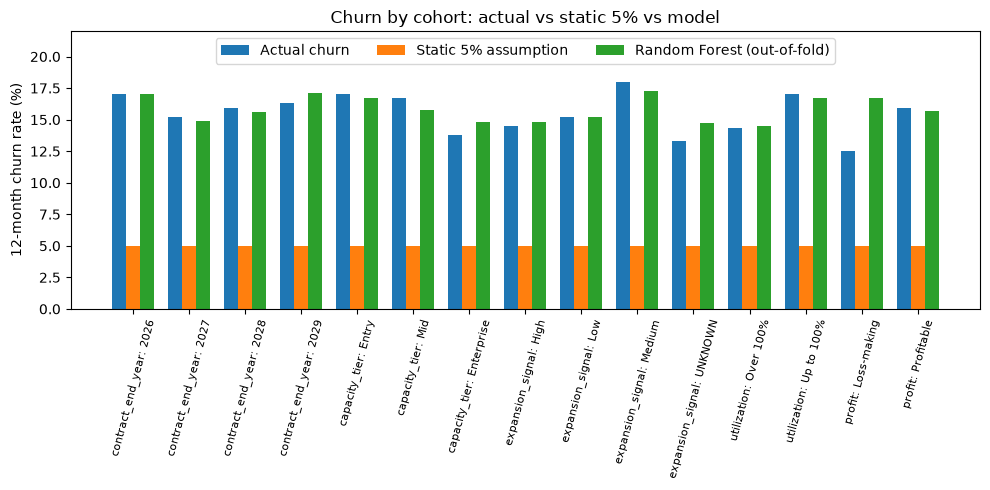

xgboost
            predicted  actual
risk_group                   
0               0.072   0.141
1               0.109   0.162
2               0.140   0.152
3               0.181   0.164
4               0.269   0.172 

random_forest
            predicted  actual
risk_group                   
0               0.106   0.143
1               0.135   0.162
2               0.156   0.168
3               0.176   0.167
4               0.215   0.151 



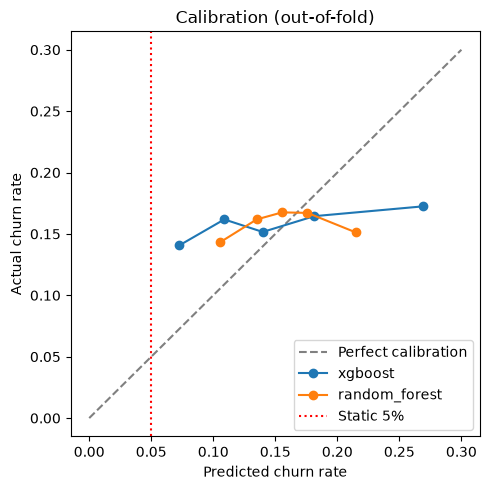

In [12]:
# Figures for the report
fig, ax = plt.subplots(figsize=(10, 5))
positions = np.arange(len(cohort_backtest))
ax.bar(positions - 0.25, cohort_backtest["actual"] * 100, 0.25, label="Actual churn")
ax.bar(positions, cohort_backtest["predicted"] * 100, 0.25, label="Static 5% assumption")
ax.bar(positions + 0.25, cohort_backtest["model_pred"] * 100, 0.25, label="Random Forest (out-of-fold)")
ax.set_xticks(positions)
ax.set_xticklabels(cohort_backtest.index, rotation=75, fontsize=8)
ax.set_ylabel("12-month churn rate (%)")
ax.set_title("Churn by cohort: actual vs static 5% vs model")
ax.set_ylim(0, 22)
ax.legend(loc="upper center", ncol=3)
plt.tight_layout()
plt.savefig("outputs/fig1_cohort_backtest.png", dpi=150)
plt.show()

# Calibration: split arrays into 5 groups by predicted risk and compare predicted vs actual churn
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot([0, 0.3], [0, 0.3], "--", color="grey", label="Perfect calibration")
for name in ["xgboost", "random_forest"]:
    calibration = pd.DataFrame({"predicted": predictions[name], "actual": y})
    calibration["risk_group"] = pd.qcut(calibration["predicted"], 5, labels=False)
    calibration = calibration.groupby("risk_group").mean()
    ax.plot(calibration["predicted"], calibration["actual"], "o-", label=name)
    print(name)
    print(calibration.round(3), "\n")
ax.axvline(BASELINE_CHURN, color="red", linestyle=":", label="Static 5%")
ax.set_xlabel("Predicted churn rate")
ax.set_ylabel("Actual churn rate")
ax.set_title("Calibration (out-of-fold)")
ax.legend()
plt.tight_layout()
plt.savefig("outputs/fig2_calibration.png", dpi=150)
plt.show()

In [13]:
# Champion = Random Forest: lower Brier score than XGBoost in the back-test above.
final_model = make_random_forest()
final_model.fit(X, y)

scored = df.copy()
scored["churn_prob_12m"] = final_model.predict_proba(X_all)[:, 1]

# Probability buckets = quartiles of the predicted churn probability (500 arrays each)
scored["risk_bucket"] = pd.qcut(scored["churn_prob_12m"], 4, labels=["LOW", "MEDIUM", "HIGH", "VERY_HIGH"])

# 15-year renewal: chance the array is still a customer after 15 years. Only 12-month outcomes
# exist, so this repeats the 12-month probability every year (year 1 validated, 2-15 extrapolated).
scored["survival_prob_15y"] = (1 - scored["churn_prob_12m"]) ** HORIZON_YEARS

print(scored.groupby("risk_bucket", observed=True)["churn_prob_12m"].agg(["count", "min", "max", "mean"]).round(3))
print()
print("Scoring set (116 arrays with no label), average churn probability:",
      round(scored.loc[unlabelled.index, "churn_prob_12m"].mean(), 4))

             count    min    max   mean
risk_bucket                            
LOW            500  0.056  0.127  0.108
MEDIUM         500  0.127  0.154  0.140
HIGH           500  0.154  0.186  0.169
VERY_HIGH      500  0.186  0.321  0.216

Scoring set (116 arrays with no label), average churn probability: 0.1606


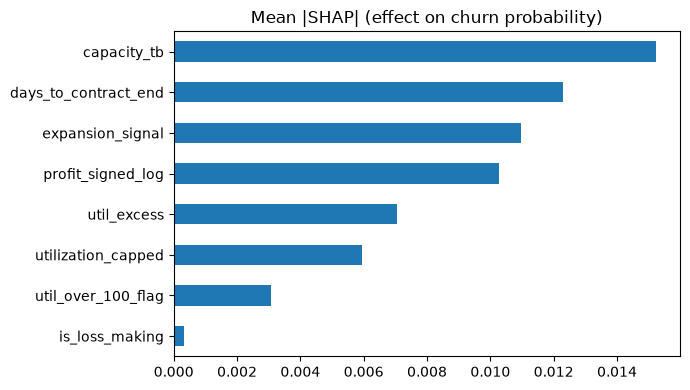

capacity_tb             0.0152
days_to_contract_end    0.0123
expansion_signal        0.0110
profit_signed_log       0.0103
util_excess             0.0070
utilization_capped      0.0059
util_over_100_flag      0.0031
is_loss_making          0.0003
dtype: float64


,array_id,churn_prob_12m,risk_bucket,top_drivers
0,ARR_5000,0.212207,VERY_HIGH,"[{""feature"": ""days_to_contract_end"", ""shap"": 0..."
1,ARR_5001,0.212385,VERY_HIGH,"[{""feature"": ""days_to_contract_end"", ""shap"": 0..."
2,ARR_5002,0.128588,MEDIUM,"[{""feature"": ""days_to_contract_end"", ""shap"": 0..."
3,ARR_5003,0.195526,VERY_HIGH,"[{""feature"": ""days_to_contract_end"", ""shap"": 0..."
4,ARR_5004,0.139816,MEDIUM,"[{""feature"": ""days_to_contract_end"", ""shap"": 0..."


In [14]:
# SHAP: how much each feature pushed each array's churn probability up or down
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_all)[:, :, 1]     # class 1 = churn
shap_table = pd.DataFrame(shap_values, columns=X_all.columns, index=X_all.index)

# The 4 expansion columns describe one field, so add them back together
expansion_columns = ["expansion_Low", "expansion_Medium", "expansion_High", "expansion_UNKNOWN"]
shap_table["expansion_signal"] = shap_table[expansion_columns].sum(axis=1)
shap_table = shap_table.drop(columns=expansion_columns)


def top_3_drivers(row):
    top = row.abs().sort_values(ascending=False).head(3).index
    return json.dumps([{"feature": name, "shap": round(float(row[name]), 4)} for name in top])


scored["top_drivers"] = shap_table.apply(top_3_drivers, axis=1)

importance = shap_table.abs().mean().sort_values()
importance.plot(kind="barh", figsize=(7, 4), title="Mean |SHAP| (effect on churn probability)")
plt.tight_layout()
plt.savefig("outputs/fig3_shap_importance.png", dpi=150)
plt.show()
print(importance.sort_values(ascending=False).round(4))
scored[["array_id", "churn_prob_12m", "risk_bucket", "top_drivers"]].head()

In [15]:
# Export: the scored table for Snowflake (CSV) and a SQL insert script for the same rows
output = pd.DataFrame({
    "ARRAY_ID": scored["array_id"],
    "ACCOUNT_ID": scored["account_id"],
    "SCORE_DATE": SCORE_DATE.strftime("%Y-%m-%d"),
    "MODEL_NAME": "random_forest",
    "MODEL_VERSION": MODEL_VERSION,
    "RUN_ID": RUN_ID,
    "HAS_LABEL": scored["churn_event_next_12m"].notna(),
    "UTILIZATION_CAPPED": X_all["utilization_capped"],
    "UTIL_OVER_100_FLAG": X_all["util_over_100_flag"],
    "UTIL_EXCESS": X_all["util_excess"],
    "CURRENT_CAPACITY_TB": scored["current_capacity_tb"],
    "NET_PROFIT_15YR_USD": scored["historical_15yr_net_profit_usd"],
    "IS_LOSS_MAKING": X_all["is_loss_making"],
    "DAYS_TO_CONTRACT_END": X_all["days_to_contract_end"],
    "EXPANSION_SIGNAL": scored["expansion_potential_signal"],
    "CHURN_PROB_12M": scored["churn_prob_12m"].round(4),
    "BASELINE_CHURN_RATE": BASELINE_CHURN,
    "RISK_BUCKET": scored["risk_bucket"].astype(str),
    "SURVIVAL_PROB_15Y": scored["survival_prob_15y"].round(4),
    "HORIZON_BASIS": "Y1_VALIDATED_Y2_15_EXTRAPOLATED",
    "TOP_DRIVERS_JSON": scored["top_drivers"],
})
output.to_csv("outputs/clv_scored_output.csv", index=False)


def sql_value(value):
    if isinstance(value, (bool, np.bool_)):
        return "TRUE" if value else "FALSE"
    if isinstance(value, str):
        return "'" + value.replace("'", "''") + "'"
    return str(value)


with open("sql/03_insert_clv_scored_output.sql", "w") as f:
    f.write("-- Generated by CLV_Predictive_Analytics.ipynb\n")
    f.write("-- Loads " + RUN_ID + " into the stage table, then the MERGE procedure moves it into CLV_SCORED_OUTPUT.\n")
    f.write("USE SCHEMA CLV_DB.ML;\n\n")
    for start in range(0, len(output), 500):
        batch = output.iloc[start:start + 500]
        f.write("INSERT INTO CLV_SCORED_STAGE (" + ", ".join(output.columns) + ") VALUES\n")
        rows = ["(" + ", ".join(sql_value(v) for v in row) + ")" for row in batch.itertuples(index=False)]
        f.write(",\n".join(rows) + ";\n\n")
    f.write("CALL SP_MERGE_CLV_SCORES('" + RUN_ID + "');\n")

print(output.shape)
output.head(3).T

(2000, 21)


,0,1,2
ARRAY_ID,ARR_5000,ARR_5001,ARR_5002
ACCOUNT_ID,ACC_1000,ACC_1001,ACC_1002
SCORE_DATE,2026-10-01,2026-10-01,2026-10-01
MODEL_NAME,random_forest,random_forest,random_forest
MODEL_VERSION,v1.0,v1.0,v1.0
RUN_ID,RUN_01,RUN_01,RUN_01
HAS_LABEL,True,True,True
UTILIZATION_CAPPED,0.59,0.93,1.0
UTIL_OVER_100_FLAG,0,0,1
UTIL_EXCESS,0.0,0.0,0.28
